In [1]:
#
#
#

import arslabrobotics as ar

import numpy as np
import scipy

delta_t = 0.016

# model identified using least-square method
(a, b) = ([-0.998308720394236], [0.06676269003659396])

# Discrete system model
system = ar.identification.ARXModel(a, b)
(A, B, C) = system.state_space()

#print(A, B, C)

# resize the matrices in order to add position as state variable
A = np.hstack( (A, np.zeros( (1,1) ) ) )
A = np.vstack( (A, np.zeros( (1,2) ) ) ) 
B = np.vstack( (B, [0]) )

A[1,0] = delta_t
A[1,1] = 1.0


print("State Matrix:\n", A)
print("Input Matrix:\n", B)


State Matrix:
 [[0.99830872 0.        ]
 [0.016      1.        ]]
Input Matrix:
 [[0.06676269]
 [0.        ]]


In [10]:

# speed has no cost, only position
Q = np.zeros( (2,2), dtype=np.float32)
Q[1,1]=0.1

R = np.eye(1, dtype=np.float32) * 10

P = scipy.linalg.solve_discrete_are(A, B, Q, R)
K = np.linalg.inv(R + B.T @ P @ B) @ B.T @ P @ A

print("Optimal Gain:", K)


Optimal Gain: [[0.19512966 0.09935074]]


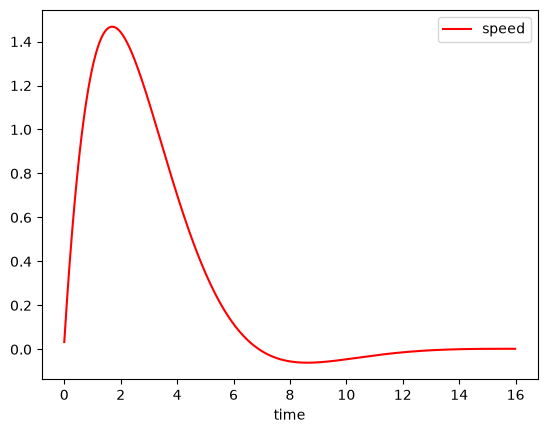

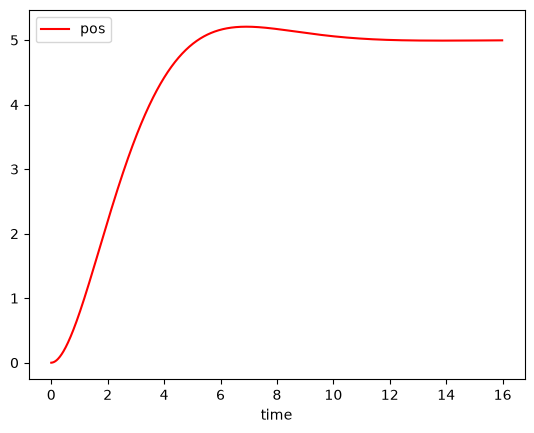

In [11]:

x = np.array([ 0., 0.])

set_point = np.array([0., 5.0])

dps = ar.data.DataPlotter()
dps.set_x("time")
dps.add_y("vz", "speed")

dpp = ar.data.DataPlotter()
dpp.set_x("time")
dpp.add_y("z", "pos")

use_godot = False
if use_godot:
    dds = ar.dds.DDS()
    dds.start()
    dds.subscribe(['VZ','Z'])
    t = ar.utils.Time(use_fake_time = False)
    t.start()
    while t.get() < 10:
        vz = dds.wait('VZ')
        z = dds.read('Z')
        __delta_t = t.elapsed()

        dds.publish('time', t.get(), ar.dds.DDS_TYPE_FLOAT)

        x = np.array([vz, z])
        x_t = x - set_point
        u = - K @ x_t
        u = u[0] + 9.81/4
        
        dds.publish('f1', u, ar.dds.DDS_TYPE_FLOAT)
        dds.publish('f2', u, ar.dds.DDS_TYPE_FLOAT)
        dds.publish('f3', u, ar.dds.DDS_TYPE_FLOAT)
        dds.publish('f4', u, ar.dds.DDS_TYPE_FLOAT)

        dps.append_x(t.get())
        dps.append_y("vz", vz)
        
        dpp.append_x(t.get())
        dpp.append_y("z", z)

else:
    x_t = x - set_point
    
    for t in range(0,1000):
        u = - K @ x_t
        x_t = A @ x_t + B @ u
        x = x_t + set_point
        dps.append_x(t*delta_t)
        dps.append_y("vz", x[0])
        dpp.append_x(t*delta_t)
        dpp.append_y("z", x[1])
    
dps.plot()
dpp.plot()
